# Ejercicio 3: Análisis estadístico de datos — PCA

**Tópicos Selectos en Aprendizaje Maquinal — TP N°1: Algoritmos para Reconocimiento de Patrones**

En este notebook se resuelve el Ejercicio 3 de la guía: se implementa el **Análisis de Componentes Principales (PCA)** y se lo aplica a dos conjuntos de datos.

| Inciso | Consigna | Idea central |
|:--|:--|:--|
| **1** | Implementar el algoritmo de PCA | Autovectores de la matriz de covarianza = direcciones de máxima varianza |
| **2** | *Iris*: reducir a 2 dimensiones y graficar por especie | Visualizar el solapamiento entre clases en el subespacio principal |
| **3** | *Tinyfaces*: obtener y graficar las 12 primeras Eigenfaces | PCA aplicado a imágenes: las componentes son "caras" |

**Contenido**

1. [Implementación de PCA](#1.-Implementación-de-PCA)
2. [Iris](#2.-Iris)
3. [Tinyfaces: Eigenfaces](#3.-Tinyfaces:-Eigenfaces)
4. [Conclusiones](#4.-Conclusiones)

In [1]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA as PCA_sklearn      # solo para validar nuestra implementación

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)

---
## 1. Implementación de PCA

> *Implemente el algoritmo de PCA.*

### 1.1 Marco teórico

Sea $\mathbf{X}\in\mathbb{R}^{N\times d}$ una matriz de datos con $N$ muestras (filas) y $d$ características (columnas). **PCA** busca un subespacio de dimensión $m<d$ sobre el cual proyectar los datos *conservando la mayor varianza posible*, es decir, perdiendo la mínima información. Es una técnica **no supervisada**: no usa etiquetas.

**Primera componente.** Se busca la dirección unitaria $\mathbf{w}_1$ tal que la proyección $z=\mathbf{w}_1^\top(\mathbf{x}-\bar{\mathbf{x}})$ tenga varianza máxima:

$$
\mathbf{w}_1=\arg\max_{\|\mathbf{w}\|=1}\ \mathbf{w}^\top\boldsymbol{\Sigma}\,\mathbf{w},
\qquad \boldsymbol{\Sigma}=\frac{1}{N-1}\sum_{n=1}^{N}(\mathbf{x}_n-\bar{\mathbf{x}})(\mathbf{x}_n-\bar{\mathbf{x}})^\top .
$$

Con un multiplicador de Lagrange se llega a $\boldsymbol{\Sigma}\mathbf{w}=\lambda\mathbf{w}$: $\mathbf{w}_1$ es el **autovector de $\boldsymbol{\Sigma}$ de mayor autovalor**, y la varianza capturada es exactamente $\lambda_1$. Las siguientes componentes son los autovectores restantes, ordenados por autovalor decreciente, y son **ortogonales** entre sí.

**Algoritmo.**

1. **Centrar** los datos: restar la media de cada característica, $\mathbf{X}_c=\mathbf{X}-\mathbf{1}\bar{\mathbf{x}}^\top$.
2. Calcular la **matriz de covarianza** $\boldsymbol{\Sigma}=\frac{1}{N-1}\mathbf{X}_c^\top\mathbf{X}_c\in\mathbb{R}^{d\times d}$.
3. **Descomposición espectral** $\boldsymbol{\Sigma}=\mathbf{V}\boldsymbol{\Lambda}\mathbf{V}^\top$. Como $\boldsymbol{\Sigma}$ es simétrica, los autovalores son reales y los autovectores ortonormales (`np.linalg.eigh`).
4. **Ordenar** los autovalores de mayor a menor y quedarse con los $m$ primeros autovectores: $\mathbf{W}=[\mathbf{v}_1,\dots,\mathbf{v}_m]\in\mathbb{R}^{d\times m}$ (**matriz de proyección**).
5. **Proyectar:** $\mathbf{Z}=\mathbf{X}_c\mathbf{W}\in\mathbb{R}^{N\times m}$.

**Reconstrucción.** Como $\mathbf{W}$ tiene columnas ortonormales, la mejor aproximación de rango $m$ (en error cuadrático) es $\hat{\mathbf{X}}=\mathbf{Z}\mathbf{W}^\top+\mathbf{1}\bar{\mathbf{x}}^\top$.

**Varianza explicada.** La varianza total es $\mathrm{tr}(\boldsymbol{\Sigma})=\sum_i\lambda_i$, por lo que la fracción retenida por las $m$ primeras componentes es $\sum_{i\le m}\lambda_i\big/\sum_{i}\lambda_i$.

> **Ambigüedad de signo.** Si $\mathbf{v}$ es autovector, también lo es $-\mathbf{v}$. Por eso el signo de cada componente no está determinado por el algoritmo. Para que los resultados sean reproducibles se fija una convención: la componente de mayor valor absoluto de cada autovector se toma positiva.

### 1.2 Implementación

In [2]:
class PCA:
    '''Análisis de Componentes Principales por descomposición espectral de la matriz de covarianza.'''

    def __init__(self, n_components):
        self.n_components = n_components

    def fit(self, X):
        X = np.asarray(X, dtype=float)

        # 1. Centrado: restar la media de cada característica
        self.media_ = X.mean(axis=0)
        Xc = X - self.media_

        # 2. Matriz de covarianza (d x d), estimador insesgado 1/(N-1)
        cov = Xc.T @ Xc / (len(X) - 1)

        # 3. Descomposición espectral (cov es simétrica -> eigh)
        autovalores, autovectores = np.linalg.eigh(cov)

        # 4. Ordenar de mayor a menor autovalor
        orden = np.argsort(autovalores)[::-1]
        autovalores, autovectores = autovalores[orden], autovectores[:, orden]

        # Convención de signo: la componente de mayor magnitud de cada autovector es positiva
        pos_max = np.argmax(np.abs(autovectores), axis=0)
        signos = np.sign(autovectores[pos_max, np.arange(autovectores.shape[1])])
        autovectores = autovectores * np.where(signos == 0, 1, signos)

        self.autovalores_ = autovalores                                   # todos (d,)
        self.componentes_ = autovectores[:, :self.n_components]           # matriz de proyección W (d x m)
        self.varianza_explicada_ = autovalores[:self.n_components]
        self.razon_varianza_ = np.clip(autovalores, 0, None) / np.clip(autovalores, 0, None).sum()
        return self

    def transform(self, X):
        '''Proyección sobre el subespacio principal: Z = (X - media) W.'''
        return (np.asarray(X, dtype=float) - self.media_) @ self.componentes_

    def inverse_transform(self, Z):
        '''Reconstrucción en el espacio original: X_hat = Z W^T + media.'''
        return Z @ self.componentes_.T + self.media_

### 1.3 Validación contra `scikit-learn`

Antes de usar la implementación se la valida con un caso conocido: las componentes y las varianzas deben coincidir con las de `sklearn.decomposition.PCA` (salvo el signo de cada componente, que no está determinado).

In [3]:
iris = load_iris()
X_iris, y_iris = iris.data, iris.target

mi_pca = PCA(n_components=4).fit(X_iris)
sk_pca = PCA_sklearn(n_components=4, svd_solver="full").fit(X_iris)

print("Varianzas (autovalores) - propia :", mi_pca.varianza_explicada_)
print("Varianzas (autovalores) - sklearn:", sk_pca.explained_variance_)
print("Componentes iguales salvo signo  :", np.allclose(np.abs(mi_pca.componentes_), np.abs(sk_pca.components_.T)))
print("Proyecciones iguales salvo signo :", np.allclose(np.abs(mi_pca.transform(X_iris)), np.abs(sk_pca.transform(X_iris))))
print("Ortonormalidad  W^T W = I        :", np.allclose(mi_pca.componentes_.T @ mi_pca.componentes_, np.eye(4)))

Varianzas (autovalores) - propia : [4.2282 0.2427 0.0782 0.0238]
Varianzas (autovalores) - sklearn: [4.2282 0.2427 0.0782 0.0238]
Componentes iguales salvo signo  : True
Proyecciones iguales salvo signo : True
Ortonormalidad  W^T W = I        : True


---
## 2. Iris

> *El dataset iris tiene 4 características medidas sobre flores de 3 variedades de la planta Iris. Para cada variedad hay 50 ejemplos, por lo que se tienen 150 ejemplos, con 4 características cada uno. Además se tiene la variedad Setosa, Versicolor, Virginica a la que corresponde cada una. Aplique una reducción dimensional a 2 dimensiones (para esto, calcule la matriz de proyección usando las 2 primeras direcciones principales), y grafique la dispersión de los datos con distintos colores para cada especie, de forma que se pueda ver en las 2 dimensiones proyectadas el grado de solapamiento de los datos.*

### 2.1 Los datos

Cada muestra tiene cuatro medidas en centímetros: largo y ancho del sépalo, y largo y ancho del pétalo. Se usa el dataset incluido en `scikit-learn` (equivalente al `iris.csv`).

In [4]:
nombres_clases = iris.target_names
nombres_feat = ["largo sépalo", "ancho sépalo", "largo pétalo", "ancho pétalo"]
print(f"X: {X_iris.shape}  |  clases: {list(nombres_clases)}  |  muestras por clase: {np.bincount(y_iris)}\n")

print(f"{'característica':<14} | {'media':>6} | {'desvío':>6}")
for nombre, col in zip(nombres_feat, X_iris.T):
    print(f"{nombre:<14} | {col.mean():6.3f} | {col.std(ddof=1):6.3f}")

X: (150, 4)  |  clases: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]  |  muestras por clase: [50 50 50]

característica |  media | desvío
largo sépalo   |  5.843 |  0.828
ancho sépalo   |  3.057 |  0.436
largo pétalo   |  3.758 |  1.765
ancho pétalo   |  1.199 |  0.762


### 2.2 Reducción a 2 dimensiones

La matriz de proyección $\mathbf{W}\in\mathbb{R}^{4\times2}$ está formada por los autovectores de los **dos mayores autovalores** de la covarianza de los datos. Cada flor de 4 dimensiones se proyecta como $\mathbf{z}=\mathbf{W}^\top(\mathbf{x}-\bar{\mathbf{x}})\in\mathbb{R}^2$.

In [5]:
pca_iris = PCA(n_components=2).fit(X_iris)
Z_iris = pca_iris.transform(X_iris)

print("Matriz de proyección W (4 x 2); columnas = PC1, PC2")
print(f"{'':<14} |    PC1 |    PC2")
for nombre, fila in zip(nombres_feat, pca_iris.componentes_):
    print(f"{nombre:<14} | {fila[0]:6.3f} | {fila[1]:6.3f}")

print("\nAutovalores de la covarianza:", pca_iris.autovalores_)
print("Varianza explicada (%)       :", pca_iris.razon_varianza_ * 100)
print(f"Varianza acumulada con 2 PC  : {pca_iris.razon_varianza_[:2].sum() * 100:.2f}%")

Matriz de proyección W (4 x 2); columnas = PC1, PC2
               |    PC1 |    PC2
largo sépalo   |  0.361 |  0.657
ancho sépalo   | -0.085 |  0.730
largo pétalo   |  0.857 | -0.173
ancho pétalo   |  0.358 | -0.075

Autovalores de la covarianza: [4.2282 0.2427 0.0782 0.0238]
Varianza explicada (%)       : [92.4619  5.3066  1.7103  0.5212]
Varianza acumulada con 2 PC  : 97.77%


### 2.3 Dispersión de los datos proyectados

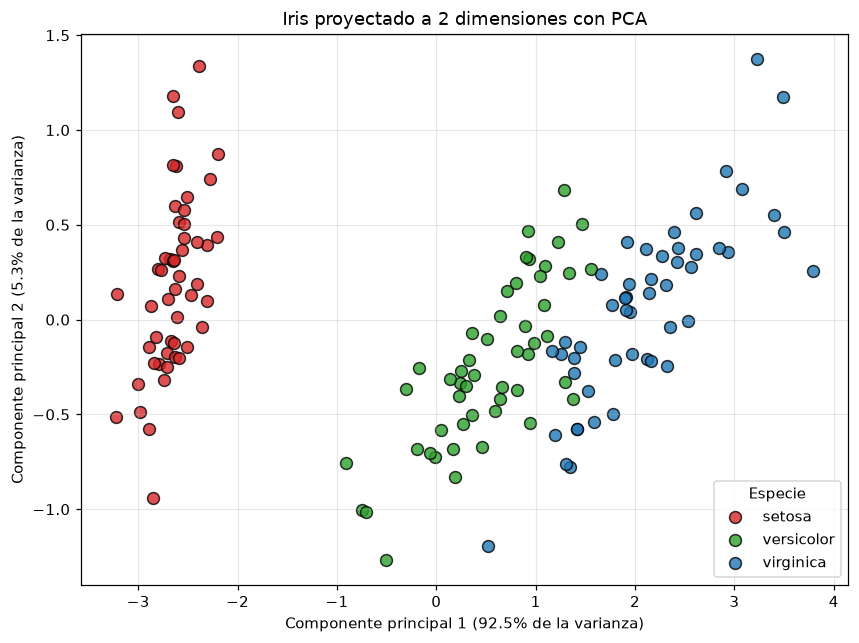

In [6]:
colores = ["#d62728", "#2ca02c", "#1f77b4"]

fig, ax = plt.subplots(figsize=(9, 6.5))
for k, (color, nombre) in enumerate(zip(colores, nombres_clases)):
    ax.scatter(Z_iris[y_iris == k, 0], Z_iris[y_iris == k, 1], color=color, label=nombre,
               alpha=0.8, edgecolor="k", s=60)
ax.set_xlabel(f"Componente principal 1 ({pca_iris.razon_varianza_[0] * 100:.1f}% de la varianza)")
ax.set_ylabel(f"Componente principal 2 ({pca_iris.razon_varianza_[1] * 100:.1f}% de la varianza)")
ax.set_title("Iris proyectado a 2 dimensiones con PCA")
ax.legend(title="Especie")
plt.show()

### 2.4 Cuantificación del solapamiento

El gráfico permite ver cualitativamente cuánto se solapan las clases. Para cuantificarlo se calcula, por clase, el acierto de un clasificador de **1 vecino más cercano con validación leave-one-out** (cada muestra se clasifica con la etiqueta de su vecino más próximo, excluyéndose a sí misma). Un acierto bajo indica que sus vecinos pertenecen a otra clase, es decir, que hay solapamiento. Se compara el resultado en el espacio proyectado (2D) con el del espacio original (4D) para ver cuánta información discriminante se pierde al reducir.

In [7]:
def acierto_1nn_loo(Z, y):
    '''Acierto por clase del 1-NN leave-one-out en el espacio Z.'''
    D = np.linalg.norm(Z[:, None, :] - Z[None, :, :], axis=2)
    np.fill_diagonal(D, np.inf)                      # una muestra no puede ser su propio vecino
    pred = y[np.argmin(D, axis=1)]
    return np.array([np.mean(pred[y == k] == k) for k in np.unique(y)]), np.mean(pred == y)


print(f"{'':<12} | {'Setosa':>7} | {'Versicolor':>10} | {'Virginica':>9} | {'Global':>7}")
for nombre, Z in [("Original (4D)", X_iris), ("PCA (2D)", Z_iris)]:
    por_clase, global_ = acierto_1nn_loo(Z, y_iris)
    print(f"{nombre:<12} | " + " | ".join(f"{a * 100:>{w}.1f}%" for a, w in zip(por_clase, [6, 9, 8])) + f" | {global_ * 100:6.1f}%")

             |  Setosa | Versicolor | Virginica |  Global


Original (4D) |  100.0% |      94.0% |     94.0% |   96.0%
PCA (2D)     |  100.0% |      94.0% |     94.0% |   96.0%


### 2.5 Efecto de la escala: PCA sobre datos estandarizados

PCA **no es invariante a la escala** de las variables: una característica con mayor varianza domina las primeras componentes. En Iris las cuatro medidas están en las mismas unidades (cm) y tienen escalas parecidas, por lo que se justifica usar los datos crudos. Si las variables tuvieran unidades distintas, convendría **estandarizarlas** ($z=(x-\mu)/\sigma$), lo cual equivale a hacer PCA sobre la matriz de *correlación*. Se compara a continuación.

Varianza explicada (datos estandarizados) (%): [72.9624 22.8508]


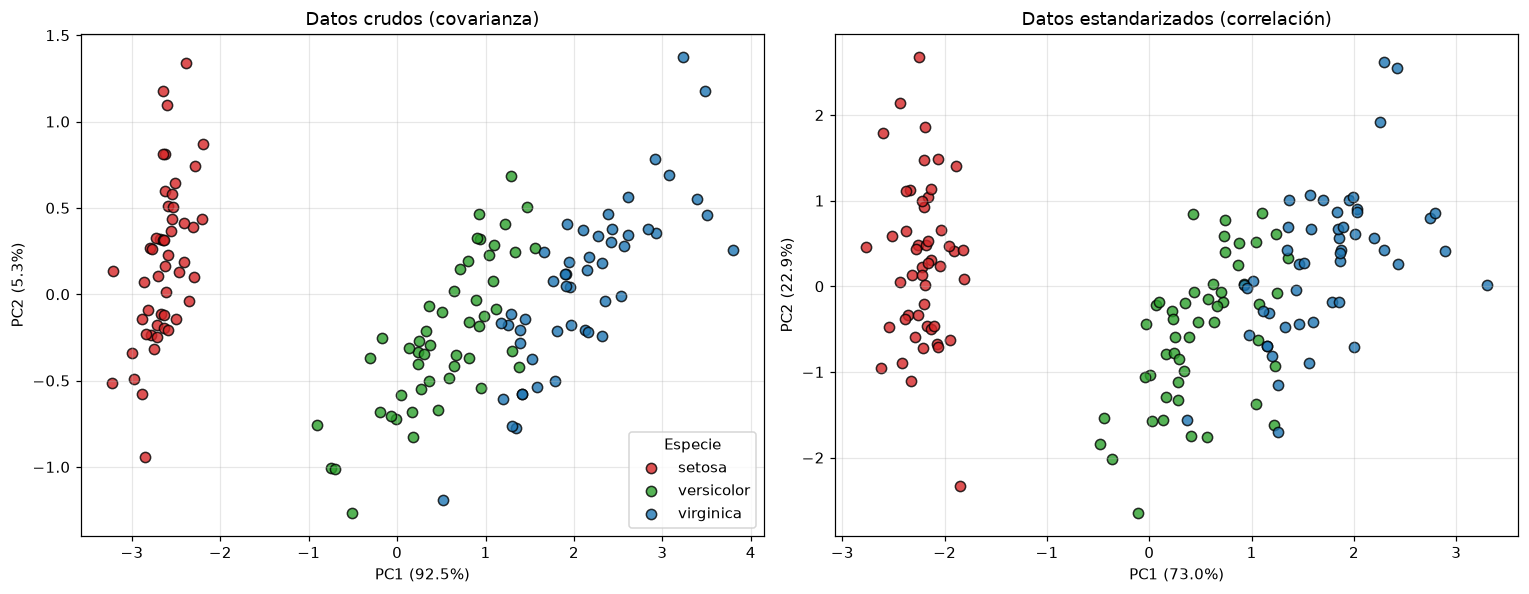

In [8]:
X_std = (X_iris - X_iris.mean(axis=0)) / X_iris.std(axis=0, ddof=1)
pca_std = PCA(n_components=2).fit(X_std)
Z_std = pca_std.transform(X_std)
print("Varianza explicada (datos estandarizados) (%):", pca_std.razon_varianza_[:2] * 100)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, Z, pca_, titulo in [(axes[0], Z_iris, pca_iris, "Datos crudos (covarianza)"),
                            (axes[1], Z_std, pca_std, "Datos estandarizados (correlación)")]:
    for k, (color, nombre) in enumerate(zip(colores, nombres_clases)):
        ax.scatter(Z[y_iris == k, 0], Z[y_iris == k, 1], color=color, label=nombre, alpha=0.8, edgecolor="k", s=45)
    ax.set_xlabel(f"PC1 ({pca_.razon_varianza_[0] * 100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca_.razon_varianza_[1] * 100:.1f}%)")
    ax.set_title(titulo)
axes[0].legend(title="Especie")
plt.tight_layout()
plt.show()

**Observaciones.**

- **Varianza retenida.** Los autovalores de la covarianza son $4.23,\ 0.24,\ 0.08,\ 0.02$. La primera componente explica el **92.5 %** de la varianza y la segunda el 5.3 %: con solo 2 de las 4 dimensiones se conserva el **97.8 %** de la varianza total, por lo que la reducción pierde muy poca información.
- **Significado de las componentes.** La PC1 está dominada por el *largo del pétalo* (peso $0.86$), con aportes menores del largo del sépalo y el ancho del pétalo ($\approx0.36$ cada uno): es básicamente un eje de "tamaño de la flor", en el que pesa sobre todo el pétalo. La PC2 combina el *ancho* y el *largo del sépalo* ($0.73$ y $0.66$).
- **Solapamiento.** *Setosa* queda completamente separada de las otras dos (acierto 1-NN del 100 %). *Versicolor* y *Virginica* se disponen en dos nubes contiguas que **se solapan parcialmente** en la zona central ($\text{PC1}\approx1$ a $2$), con un acierto 1-NN de 94 % para cada una. Esto coincide con lo observado en el gráfico: no pueden separarse perfectamente, pero la mayoría de las muestras tiene como vecino más cercano a otra de su misma especie.
- **Pérdida por la reducción.** El acierto 1-NN es el mismo en el espacio original de 4 dimensiones que en el proyectado a 2 (96 % global). Es decir, para esta tarea no se perdió información discriminante al pasar de 4D a 2D.
- **PCA no usa las etiquetas.** Que las especies resulten visibles en la proyección es una consecuencia de que, en Iris, la dirección de mayor varianza (PC1) coincide con la que más las distingue. No está garantizado en general (para buscar la separación entre clases se usan técnicas supervisadas, como LDA).
- **Efecto de la escala.** Al estandarizar las variables, la varianza se reparte de otra forma (73.0 % en PC1 y 22.9 % en PC2) y la nube cambia de forma, porque el ancho del sépalo, de menor varianza original, pasa a tener el mismo peso que las demás. Aun así se mantiene el patrón: *Setosa* aislada y *Versicolor*/*Virginica* contiguas y solapadas.

---
## 3. Tinyfaces: Eigenfaces

> *En el directorio tinyfaces_20 se encuentran 112 imágenes en formato .jpg que fueron extraídas de los 20 primeros individuos del conjunto de entrenamiento de la base de datos tinyface. Estas consisten en imágenes de rostros en baja resolución (máximo 32 por 32 píxeles). Utilice este dataset para determinar las primeras 12 Eigenfaces. Las Eigenfaces son importantes en distintas tareas asociadas al reconocimiento de rostros, y se obtienen como los autovectores de la matriz de covarianza.*

### 3.1 Marco teórico

Una imagen en escala de grises de $32\times32$ píxeles se **vectoriza** concatenando sus filas en un vector $\mathbf{x}\in\mathbb{R}^{1024}$. Un conjunto de $N$ imágenes de rostros forma entonces una nube de $N$ puntos en $\mathbb{R}^{1024}$. Como los rostros comparten una estructura común (ojos, nariz, boca en posiciones similares), esa nube ocupa un subespacio mucho más pequeño que el espacio completo de imágenes.

Las **Eigenfaces** son las componentes principales de ese conjunto: los autovectores de la matriz de covarianza de las imágenes. Como cada autovector tiene 1024 elementos, puede **reordenarse como una imagen de $32\times32$** y visualizarse como una "cara fantasma" (de ahí el nombre). Interpretación:

- La **cara promedio** $\bar{\mathbf{x}}$ es el punto de partida.
- Cada eigenface $\mathbf{v}_i$ es una **dirección de variación** respecto de la cara promedio (iluminación, forma general, barba, peinado, etc.).
- Cualquier rostro se aproxima como combinación lineal: $\mathbf{x}\approx\bar{\mathbf{x}}+\sum_{i=1}^{m}z_i\,\mathbf{v}_i$, con coeficientes $z_i=\mathbf{v}_i^\top(\mathbf{x}-\bar{\mathbf{x}})$. Los $m$ coeficientes constituyen una representación compacta del rostro, útil para reconocimiento y compresión.

**Rango de la covarianza.** Hay $N=112$ imágenes pero $d=1024$ dimensiones. Como los datos centrados suman cero, la matriz de covarianza ($1024\times1024$) tiene **rango a lo sumo $N-1=111$**: solo hay 111 autovalores no nulos, y el resto es cero (a menos del error numérico). Esto no afecta el pedido (las 12 primeras eigenfaces), pero explica la forma de la curva de varianza explicada que se verá luego.

### 3.2 a) Lectura y preprocesamiento de las imágenes

Cada imagen se lee, se convierte a **escala de grises** y se **remuestrea a $32\times32$**. Se arma una matriz de $112\times1024$ con una imagen por fila. Las imágenes originales tienen tamaños distintos (hasta $32\times32$, algunas más chicas o no cuadradas); al llevarlas todas al máximo tamaño común se ensanchan levemente las que son menores. Los archivos se ordenan alfabéticamente para que el resultado sea reproducible (`glob` no garantiza ningún orden).

In [9]:
directorio = "tinyface_20"
rutas = sorted(glob.glob(os.path.join(directorio, "*.jpg")))
print(f"{len(rutas)} imágenes encontradas en '{directorio}/'")

tam = (32, 32)
tamanos_orig = [Image.open(r).size for r in rutas]
print(f"Tamaño original: ancho {min(t[0] for t in tamanos_orig)}-{max(t[0] for t in tamanos_orig)} px, "
      f"alto {min(t[1] for t in tamanos_orig)}-{max(t[1] for t in tamanos_orig)} px")

# Escala de grises ('L') + remuestreo a 32x32 + vectorización por filas
imagenes = [np.asarray(Image.open(r).convert("L").resize(tam), dtype=float) for r in rutas]
X_caras = np.array([im.flatten() for im in imagenes])          # (112, 1024)
print("Matriz de datos:", X_caras.shape, "| rango de intensidades:", X_caras.min(), "-", X_caras.max())

112 imágenes encontradas en 'tinyface_20/'
Tamaño original: ancho 18-32 px, alto 23-32 px
Matriz de datos: (112, 1024) | rango de intensidades: 0.0 - 255.0


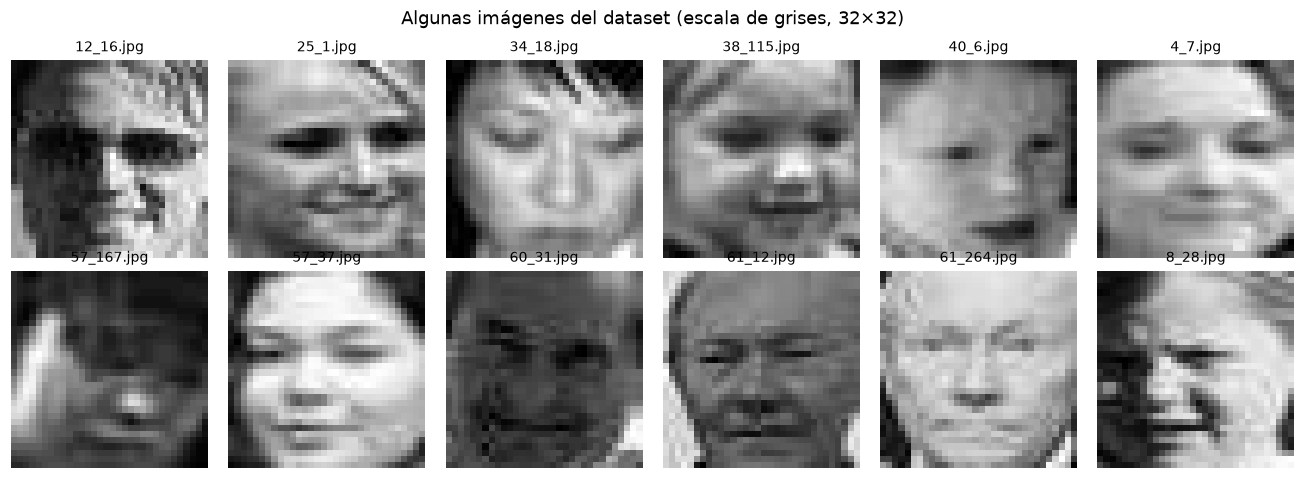

In [10]:
# Muestra de las imágenes ya procesadas (12 elegidas a intervalos regulares)
idx_muestra = np.linspace(0, len(imagenes) - 1, 12).astype(int)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for ax, i in zip(axes.flat, idx_muestra):
    ax.imshow(imagenes[i], cmap="gray")
    ax.set_title(os.path.basename(rutas[i]), fontsize=9)
    ax.axis("off")
fig.suptitle("Algunas imágenes del dataset (escala de grises, 32×32)")
plt.tight_layout()
plt.show()

### 3.3 b) Cara promedio, centrado y matriz de covarianza

Se resta a cada imagen la **cara promedio** (la media de cada píxel) y se calcula la matriz de covarianza de $1024\times1024$. Esos pasos los realiza internamente el método `fit` de la clase `PCA`; aquí se muestran explícitamente para ilustrarlos.

Matriz de covarianza: (1024, 1024) | rango numérico: 111


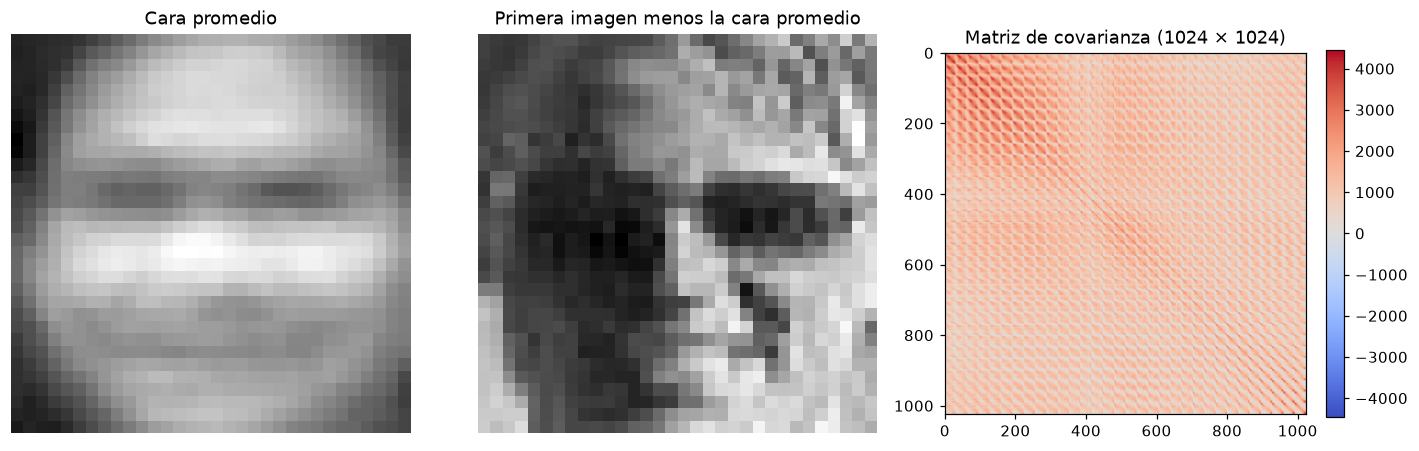

In [11]:
cara_media = X_caras.mean(axis=0)
X_centrado = X_caras - cara_media
cov_caras = X_centrado.T @ X_centrado / (len(X_caras) - 1)
print("Matriz de covarianza:", cov_caras.shape, "| rango numérico:", np.linalg.matrix_rank(cov_caras))

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
axes[0].imshow(cara_media.reshape(32, 32), cmap="gray"); axes[0].set_title("Cara promedio"); axes[0].axis("off")
axes[1].imshow(X_centrado[0].reshape(32, 32), cmap="gray"); axes[1].set_title("Primera imagen menos la cara promedio"); axes[1].axis("off")
im = axes[2].imshow(cov_caras, cmap="coolwarm", vmin=-np.abs(cov_caras).max(), vmax=np.abs(cov_caras).max())
axes[2].set_title("Matriz de covarianza (1024 × 1024)"); axes[2].grid(False)
fig.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout()
plt.show()

### 3.4 c) Autovectores de los 12 mayores autovalores

Se aplica el PCA implementado con $m=12$ componentes. La columna $i$ de `componentes_` es la $i$-ésima eigenface (vector de 1024 elementos).

In [12]:
pca_caras = PCA(n_components=12).fit(X_caras)
print("Forma de la matriz de proyección W:", pca_caras.componentes_.shape)

print("\nLos 12 mayores autovalores y su varianza explicada:")
print(f"{'#':>3} | {'autovalor':>12} | {'% varianza':>10} | {'% acumulado':>11}")
acum = np.cumsum(pca_caras.razon_varianza_)
for i in range(12):
    print(f"{i + 1:>3} | {pca_caras.autovalores_[i]:12.1f} | {pca_caras.razon_varianza_[i] * 100:10.2f} | {acum[i] * 100:11.2f}")

# Validación contra sklearn (salvo signo)
# svd_solver="full": con pocas componentes y muchas dimensiones, "auto" elegiría un solver aleatorizado (aproximado)
sk_caras = PCA_sklearn(n_components=12, svd_solver="full").fit(X_caras)
print("\nAutovalores coinciden con sklearn:", np.allclose(pca_caras.varianza_explicada_, sk_caras.explained_variance_))
print("Eigenfaces coinciden con sklearn (salvo signo):",
      np.allclose(np.abs(pca_caras.componentes_), np.abs(sk_caras.components_.T), atol=1e-6))

Forma de la matriz de proyección W: (1024, 12)

Los 12 mayores autovalores y su varianza explicada:
  # |    autovalor | % varianza | % acumulado
  1 |    1153469.9 |      40.58 |       40.58
  2 |     358582.5 |      12.61 |       53.19
  3 |     230637.2 |       8.11 |       61.31
  4 |     179909.2 |       6.33 |       67.63
  5 |      68032.0 |       2.39 |       70.03
  6 |      63275.2 |       2.23 |       72.25
  7 |      61955.1 |       2.18 |       74.43
  8 |      56833.4 |       2.00 |       76.43
  9 |      39523.5 |       1.39 |       77.82
 10 |      34506.6 |       1.21 |       79.04
 11 |      31174.7 |       1.10 |       80.13
 12 |      29326.8 |       1.03 |       81.16

Autovalores coinciden con sklearn: True
Eigenfaces coinciden con sklearn (salvo signo): True


### 3.5 d) Gráfico de las 12 Eigenfaces

Cada autovector de $1024\times1$ se reordena en una matriz de $32\times32$ (deshaciendo la vectorización por filas) y se grafica en un arreglo de $4\times3$ subimágenes. Se usa una escala de color simétrica alrededor de cero (gris = 0, claro = valores positivos, oscuro = negativos) para que se vea el signo de cada contribución.

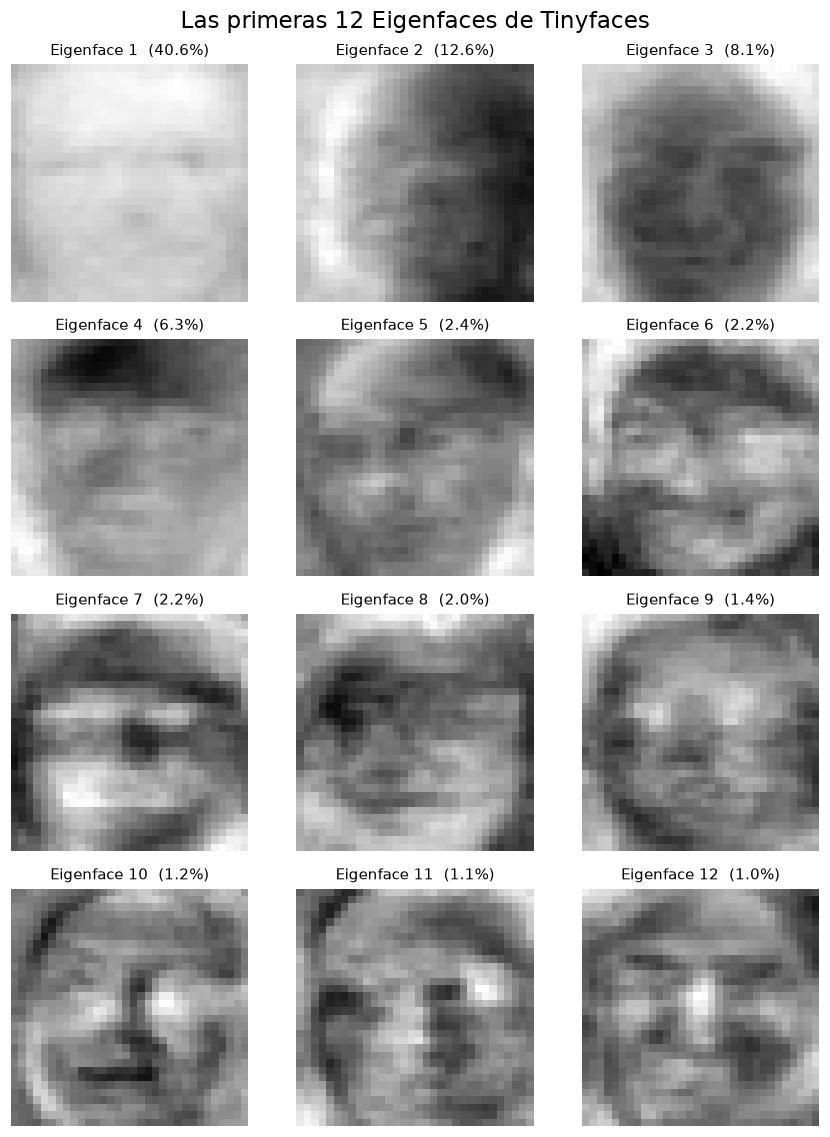

In [13]:
fig, axes = plt.subplots(4, 3, figsize=(8, 10.5))
fig.suptitle("Las primeras 12 Eigenfaces de Tinyfaces", fontsize=15)
for i, ax in enumerate(axes.flat):
    ef = pca_caras.componentes_[:, i].reshape(32, 32)               # deshacer la vectorización
    lim = np.abs(ef).max()
    ax.imshow(ef, cmap="gray", vmin=-lim, vmax=lim)
    ax.set_title(f"Eigenface {i + 1}  ({pca_caras.razon_varianza_[i] * 100:.1f}%)", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Observaciones.**

- **Varianza.** Los autovalores decrecen rápido: la primera eigenface explica el 40.6 % de la varianza, las cuatro primeras el 67.6 % y las 12 en conjunto el **81.2 %**. Las eigenfaces coinciden con las de `scikit-learn` (con `svd_solver="full"`) salvo el signo, que es arbitrario.
- **Interpretación** (cualitativa). Las primeras componentes capturan variaciones **globales**, sobre todo de **iluminación**, y no rasgos propios de un individuo:
  - la **eigenface 1** es casi uniforme: corresponde al *brillo general* de la imagen (rostros más claros o más oscuros);
  - la **2** es un gradiente horizontal (izquierda clara, derecha oscura): *iluminación lateral*;
  - la **3** contrasta el centro del rostro con sus bordes y el fondo;
  - la **4** es un gradiente vertical, con la zona de la frente/cabello oscura.

  A partir de la 5 aparecen estructuras cada vez más **finas y localizadas** (zonas de ojos, nariz, boca y contorno) y las imágenes se ven más "ruidosas", porque cada una explica una fracción menor de la varianza. Que la iluminación domine las primeras componentes es un resultado conocido en Eigenfaces cuando las fotos no tienen iluminación controlada.
- **Limitaciones del dataset.** Las imágenes son de muy baja resolución, no están alineadas ni normalizadas (distinto encuadre y escala) y se llevaron a $32\times32$ sin conservar la relación de aspecto original. Todo esto vuelve las eigenfaces menos nítidas que las clásicas de bases alineadas.

### 3.6 Extra: varianza explicada y reconstrucción de rostros

Para ver qué tan bien "resumen" las eigenfaces a los rostros, se calcula la varianza acumulada en función del número de componentes y se **reconstruyen** algunos rostros con $m$ componentes: $\hat{\mathbf{x}}=\bar{\mathbf{x}}+\sum_{i=1}^{m}z_i\mathbf{v}_i$.

Componentes para retener el 50% de la varianza: 2
Componentes para retener el 80% de la varianza: 11
Componentes para retener el 90% de la varianza: 26
Componentes para retener el 95% de la varianza: 43
Componentes para retener el 99% de la varianza: 79


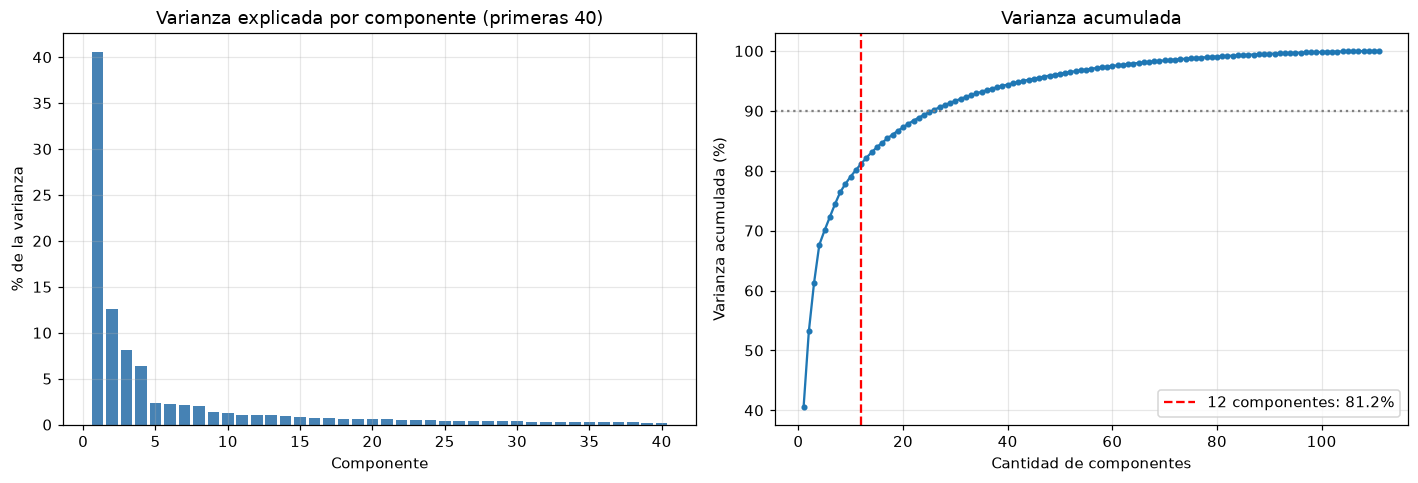

In [14]:
pca_full = PCA(n_components=111).fit(X_caras)          # 111 = rango máximo (N - 1)
var_acum = np.cumsum(pca_full.razon_varianza_)[:111]
for porcentaje in [50, 80, 90, 95, 99]:
    print(f"Componentes para retener el {porcentaje}% de la varianza: {np.searchsorted(var_acum, porcentaje / 100) + 1}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.bar(np.arange(1, 41), pca_full.razon_varianza_[:40] * 100, color="steelblue")
ax1.set_xlabel("Componente"); ax1.set_ylabel("% de la varianza")
ax1.set_title("Varianza explicada por componente (primeras 40)")
ax2.plot(np.arange(1, 112), var_acum * 100, "o-", ms=3)
ax2.axvline(12, color="r", ls="--", label=f"12 componentes: {var_acum[11] * 100:.1f}%")
ax2.axhline(90, color="gray", ls=":")
ax2.set_xlabel("Cantidad de componentes"); ax2.set_ylabel("Varianza acumulada (%)")
ax2.set_title("Varianza acumulada")
ax2.legend()
plt.tight_layout()
plt.show()

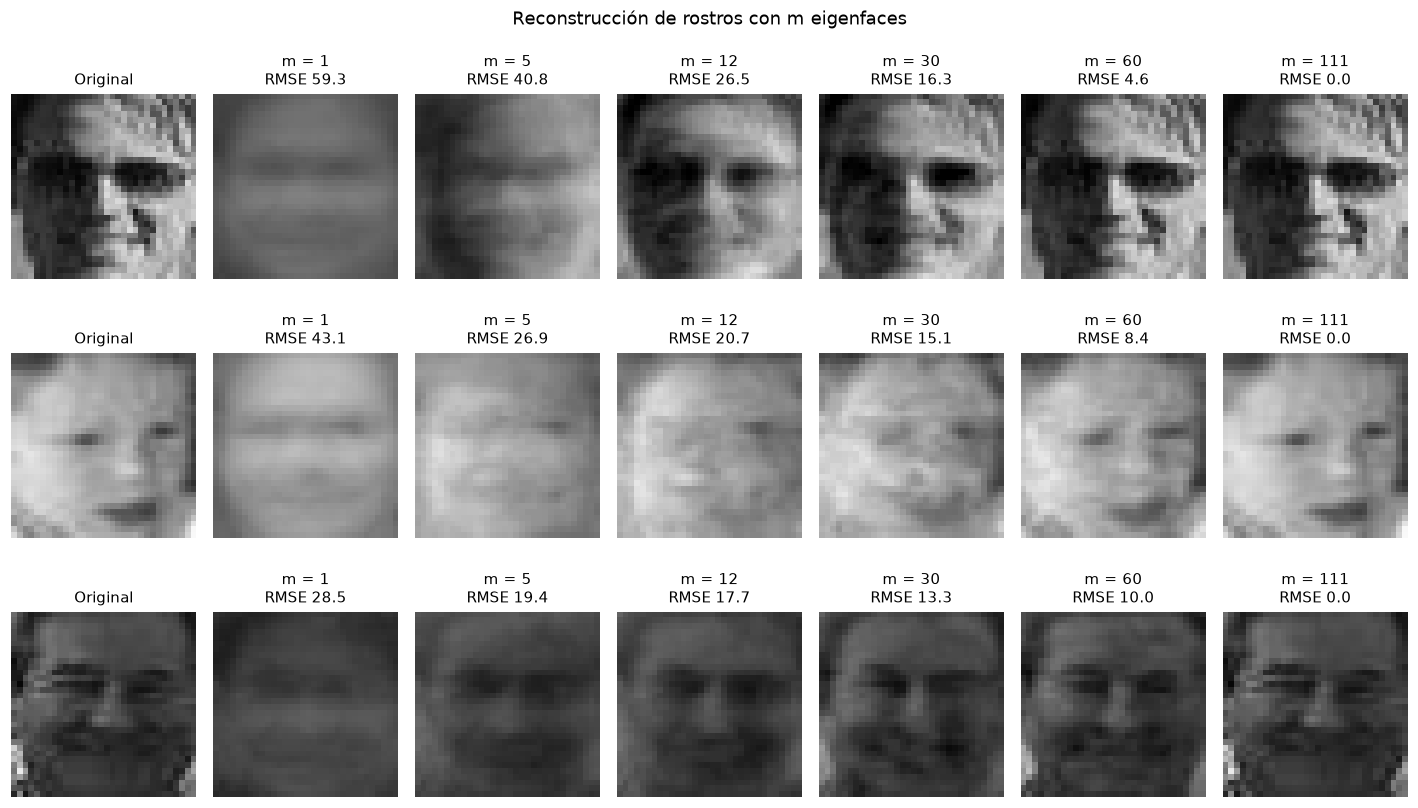

In [15]:
ms = [1, 5, 12, 30, 60, 111]
caras_ej = [0, 40, 85]                                  # tres rostros a reconstruir

fig, axes = plt.subplots(len(caras_ej), len(ms) + 1, figsize=(13, 7.8))
for fila, i in enumerate(caras_ej):
    axes[fila, 0].imshow(imagenes[i], cmap="gray", vmin=0, vmax=255)
    axes[fila, 0].set_title("Original", fontsize=10)
    for col, m in enumerate(ms, start=1):
        p = PCA(n_components=m).fit(X_caras)
        rec = p.inverse_transform(p.transform(X_caras[i:i + 1]))[0].reshape(32, 32)
        rmse = np.sqrt(np.mean((rec - imagenes[i]) ** 2))
        axes[fila, col].imshow(rec, cmap="gray", vmin=0, vmax=255)
        axes[fila, col].set_title(f"m = {m}\nRMSE {rmse:.1f}", fontsize=10)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Reconstrucción de rostros con m eigenfaces")
plt.tight_layout()
plt.show()

**Observaciones.**

- **Varianza acumulada.** Las 12 eigenfaces retienen el 81 % de la varianza; se necesitan 26 para el 90 %, 43 para el 95 % y 79 para el 99 %. La mitad de la varianza ya está en las 2 primeras componentes.
- **Reconstrucción.** Con $m=1$ se obtiene prácticamente la cara promedio ajustada en brillo; con $m=12$ ya se recuperan la iluminación y los rasgos generales (por ejemplo, la sombra lateral y los anteojos del primer rostro); los detalles finos recién aparecen con $m\approx30$ a $60$. El error (RMSE) disminuye de forma monótona al aumentar $m$.
- **Compresión.** Con $m=12$, cada rostro de 1024 valores se representa con 12 coeficientes (una reducción de ~85 veces) conservando el 81 % de la varianza.
- **Cuidado con $m=111$.** El error es nulo porque las imágenes de entrenamiento generan *exactamente* el subespacio de dimensión 111 (el rango de la covarianza). No es una prueba de buen desempeño: con rostros nuevos, no vistos en el ajuste, el error de reconstrucción no sería cero.

---
## 4. Conclusiones

1. **PCA.** El algoritmo se reduce a centrar los datos, calcular la covarianza y diagonalizarla: los autovectores (ordenados por autovalor decreciente) son las direcciones de máxima varianza, y cada autovalor es la varianza capturada a lo largo de la suya. La implementación propia coincide con `scikit-learn` salvo el signo de las componentes, que no está determinado.
2. **Iris.** Dos componentes retienen el 97.8 % de la varianza. En la proyección, *Setosa* es separable por completo, mientras que *Versicolor* y *Virginica* se solapan parcialmente (acierto 1-NN de 94 % en cada una), igual que en el espacio original de 4 dimensiones. PCA no es invariante a la escala: con variables en unidades distintas conviene estandarizar.
3. **Eigenfaces.** Las componentes principales de un conjunto de rostros, reordenadas como imágenes, son "caras fantasma". Las primeras (81 % de la varianza con 12) capturan sobre todo iluminación global, y las siguientes detalles más finos. Cualquier rostro se aproxima como la cara promedio más una combinación lineal de eigenfaces, lo que da una representación compacta (12 números en vez de 1024).
4. **Rango.** Con $N=112$ imágenes y $d=1024$ píxeles la covarianza tiene rango a lo sumo 111: solo hay 111 componentes con varianza no nula.